# Predicting the plan from the frozen VLM: a regressed contact against a map over image cells
**VLA direction** · LIBERO-PRO (arXiv 2510.03827), Object suite · released starVLA checkpoint `Qwen3-VL-PI-LIBERO-4in1`, VLM frozen · 13 Nov 2026 · the first closed loop without an oracle plan

- **The question:** the notebook of 12 Nov showed that an action head trained to obey a plan solves most perturbed tasks when the plan is right. Here the plan is predicted from the camera images and the instruction. Does a predicted plan point at the right place when the target has moved or another object is asked for, and how much of the oracle result is left?
- **Real:** both plan predictors and everything they output; the action head (trained with counterfactual plans on six of the ten tasks, 11 Nov); all rollouts; the benchmark's scenes, start states and goal checks.
- **ORACLE:** the training targets of the predictors (the contact of the next gripper event in the demonstrations, from simulator state), the contacts drawn as rings in the pictures, and the last column of the closed-loop table, which is given the oracle plan as an upper bound. The camera calibration used by the map head is taken from the simulator.
- **Protocol:** the predictors saw only standard LIBERO-Object demonstrations (454 demonstrations of ten tasks, of which 5 per task were kept out for testing). Closed loop: 10 tasks × 20 start states (0–19) per perturbation; the benchmark's papers use 50. One run, one seed.

```text
(1) the two predictors                                       real (trained here on ORACLE targets)
        ↓
(2) contact error on frames they never trained on            real predictions against ORACLE contacts
        ↓
(3) the same in pictures; the map over image cells           real
        ↓
(4) closed loop on LIBERO-PRO: predicted plan → action head  real rollouts; last column ORACLE
        ↓
(5) where the plans pointed during the rollouts              real
        ↓
(6) what happened to the named object                        real
```

<sub>To re-run on the A6000 server, through the GPU queue: `scripts/remote/run_plan_predictor_gpu.sh` with `RUN=p1 HEAD=regress` and `RUN=g1 HEAD=grid`; `scripts/remote/run_libero_pro_gpu.sh` with `NAME=predicted_g1 ADAPTER=s2_actions PLAN=predicted PREDICTOR=g1` (add `HOLD=1` and `NAME=predicted_g1_hold` for the kept plan; the same for `p1`); then execute this notebook.</sub>

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Video, display
from matplotlib_inline.backend_inline import set_matplotlib_formats

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "affordance3d").is_dir())
sys.path.insert(0, str(ROOT))
from affordance3d.plan_grid import camera_of_log
from affordance3d.plan_input import offsets_from_json
from affordance3d.rollout_log import load_rollout_log
from report import libero_pro_helpers as L
from report import plan_predictor_helpers as P
from report import vla_pipeline_demo_helpers as H

set_matplotlib_formats("jpeg")
plt.rcParams.update({"figure.dpi": 90})
pd.set_option("display.max_colwidth", 120)

REGRESS, GRID = "regressed contact", "map over image cells"
PREDICTORS = {REGRESS: ROOT / "runs" / "plan_predictor" / "p1", GRID: ROOT / "runs" / "plan_predictor" / "g1"}
metrics = {name: P.load_metrics(run) for name, run in PREDICTORS.items()}
found = {name: P.load_predictions(run) for name, run in PREDICTORS.items()}
P.check_same_items(found)
DEMO = ROOT / "runs" / "plan_following" / "demos" / "pick_up_the_salad_dressing_and_place_it_in_the_basket_demo0.npz"
camera = camera_of_log(load_rollout_log(DEMO))
offsets = offsets_from_json((ROOT / "runs" / "plan_following" / "dataset10" / "offsets.json").read_text())
print({name: sorted(facts["held_out"]) + sorted(facts["benchmark"]) for name, facts in metrics.items()})

{'regressed contact': ['other: grasp', 'own: grasp', 'own: release', 'pro libero_object_swap: grasp', 'pro libero_object_task: grasp'], 'map over image cells': ['other: grasp', 'own: grasp', 'own: release', 'pro libero_object_swap: grasp', 'pro libero_object_task: grasp']}


## 1 · The two predictors
**This step:** both read the hidden states of the frozen VLM (36 layers, about 180 tokens: 64 per camera image, then the instruction) and output the next gripper event (grasp, release, none), where the gripper should be at that event, and the direction it should arrive from. They differ in how the place is given.

- **Regressed contact:** four learned queries read the whole token sequence and output three world coordinates.
- **Map over image cells:** each of the 8 × 8 image tokens of the agent view gets a score, "the contact is seen in this cell", plus the position inside the cell and the depth along the viewing ray. The best cell, its offset and its depth give the 3D contact through the camera calibration. Because the VLM reads the images before the instruction, a small two-layer encoder lets the cells read the instruction first. In training the agent view is shifted at random by up to two cells and the target cell moves with it.

**Status:** real. Both are trained on the same frames. A frame before the grasp is also given with an instruction that names another object of the scene, whose grasp point is then the target; this needs no extra demonstrations. The table gives sizes and training length.

In [2]:
display(P.facts_table(metrics))

,regressed contact,map over image cells
trained parameters (millions),10.78,7.89
training steps,3000.00,2500.00
frames per step,8.00,8.00
training frames to draw from,56852.00,56852.00
test items from held-out demonstrations,618.00,618.00
LIBERO-PRO start frames,40.00,40.00
peak GPU memory (GiB),16.53,16.56


## 2 · Contact error on frames the predictors never trained on
**This step:** the predicted contact against the oracle contact, in centimetres, on five sets of frames: held-out demonstrations under their own instruction (next grasp, next release), the same frames with another object named, and the first frame of LIBERO-PRO rollouts under each perturbation (two start states per task).

**Status:** real predictions; the contacts they are compared with are ORACLE. "Another object nearer" counts the items whose predicted contact lies closer to another object's grasp point than to the right one: the plan points at the wrong object.

In [3]:
display(P.offline_table(metrics))

\
                                                            items   
held-out demonstrations, own instruction: next grasp           98   
held-out demonstrations, own instruction: next release         30   
held-out demonstrations, another object named                 490   
LIBERO-PRO start frames: another object asked for              20   
LIBERO-PRO start frames: target swapped with another object    20   

                                                            regressed contact  \
                                                            median error (cm)   
held-out demonstrations, own instruction: next grasp                     1.13   
held-out demonstrations, own instruction: next release                   1.31   
held-out demonstrations, another object named                            2.71   
LIBERO-PRO start frames: another object asked for                        3.71   
LIBERO-PRO start frames: target swapped with another object             22.89   

                                                                         \
                                                            within 2 cm   
held-out demonstrations, own instruction: next grasp              0.878   
held-out demonstrations, own instruction: next release            0.833   
held-out demonstrations, another object named                     0.365   
LIBERO-PRO start frames: another object asked for                 0.400   
LIBERO-PRO start frames: target swapped with another object       0.000   

                                                                                   \
                                                            another object nearer   
held-out demonstrations, own instruction: next grasp                        0.020   
held-out demonstrations, own instruction: next release                      0.000   
held-out demonstrations, another object named                               0.222   
LIBERO-PRO start frames: another object asked for                           0.250   
LIBERO-PRO start frames: target swapped with another object                 1.000   

                                                                         \
                                                            event right   
held-out demonstrations, own instruction: next grasp               0.98   
held-out demonstrations, own instruction: next release             1.00   
held-out demonstrations, another object named                      0.98   
LIBERO-PRO start frames: another object asked for                  1.00   
LIBERO-PRO start frames: target swapped with another object        1.00   

                                                            map over image cells  \
                                                               median error (cm)   
held-out demonstrations, own instruction: next grasp                        0.61   
held-out demonstrations, own instruction: next release                      0.92   
held-out demonstrations, another object named                               1.08   
LIBERO-PRO start frames: another object asked for                           1.32   
LIBERO-PRO start frames: target swapped with another object                 1.94   

                                                                         \
                                                            within 2 cm   
held-out demonstrations, own instruction: next grasp              0.939   
held-out demonstrations, own instruction: next release            1.000   
held-out demonstrations, another object named                     0.835   
LIBERO-PRO start frames: another object asked for                 1.000   
LIBERO-PRO start frames: target swapped with another object       0.550   

                                                                                   \
                                                            another object nearer   
held-out demonstrations, own instruction: next grasp                        0.031 

## 3 · The same in pictures, and the map
**This step:** the first frame of one rollout per task, under each perturbation. The ring is the oracle grasp point of the object asked for; the markers are the two predictions, projected into the image. Below them, the scores the map head gives to the 64 cells for the position perturbation.

**Status:** real predictions on images the predictors never saw; ring = ORACLE.

position: the target swaps places with another object


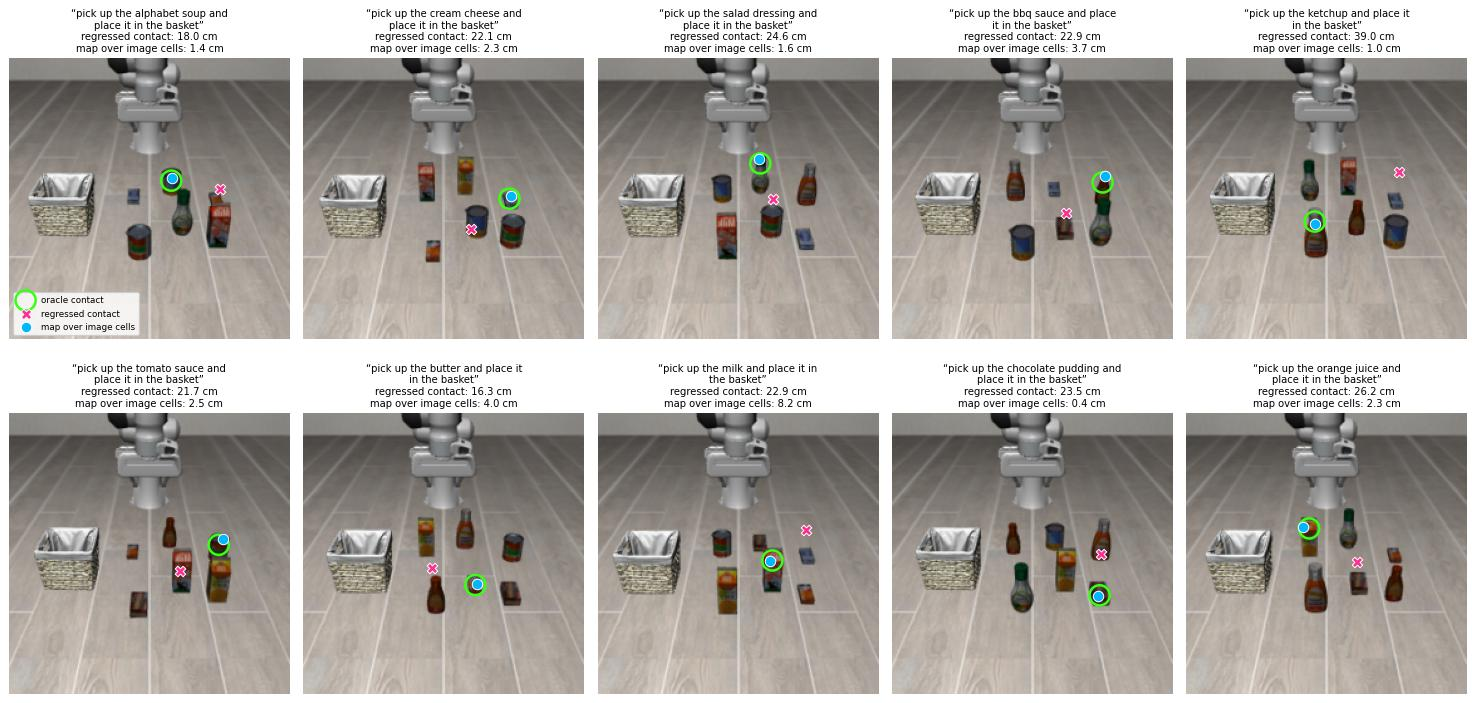

task: the instruction and the goal name another object


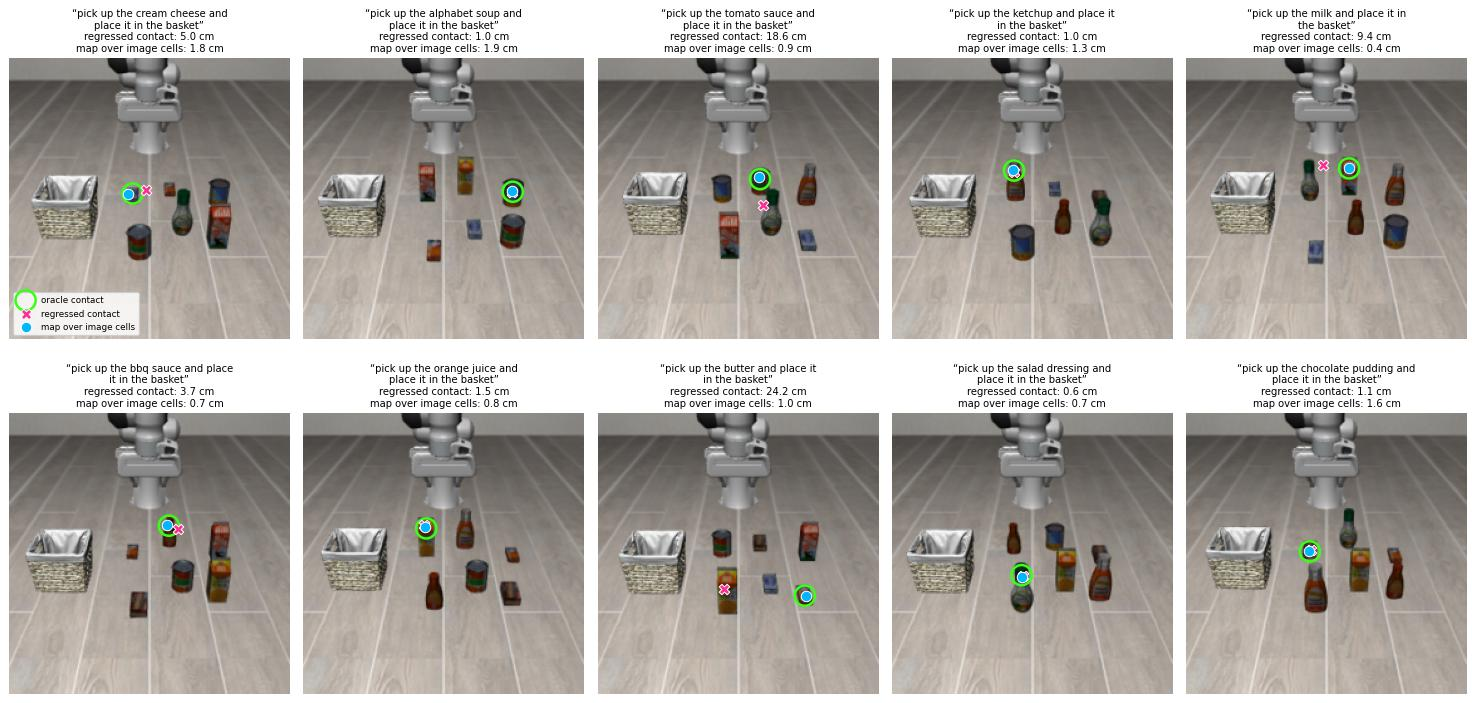

In [4]:
for label, suite in L.SUITES.items():
    print(label)
    P.prediction_figure(found, camera, P.items_of(found[REGRESS], f"pro {suite}", every=2))
    plt.show()

map over image cells · position: the target swaps places with another object


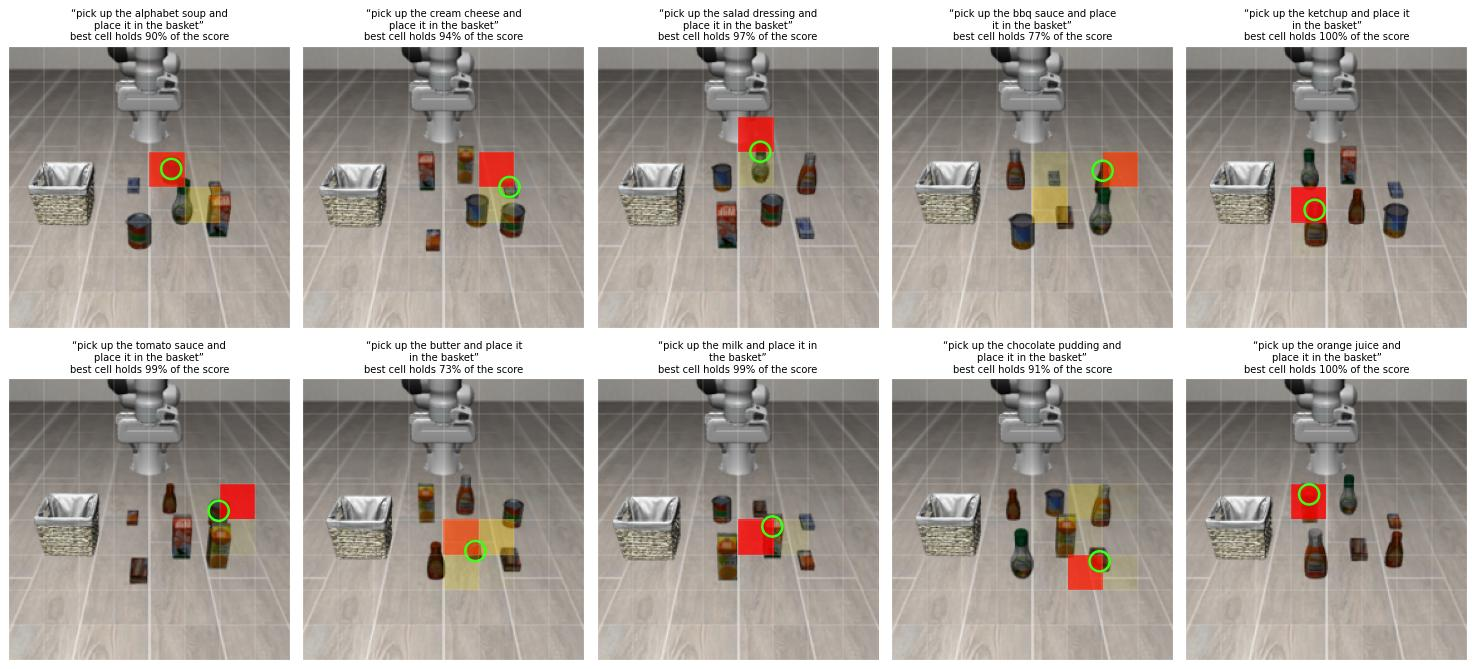

map over image cells · task: the instruction and the goal name another object


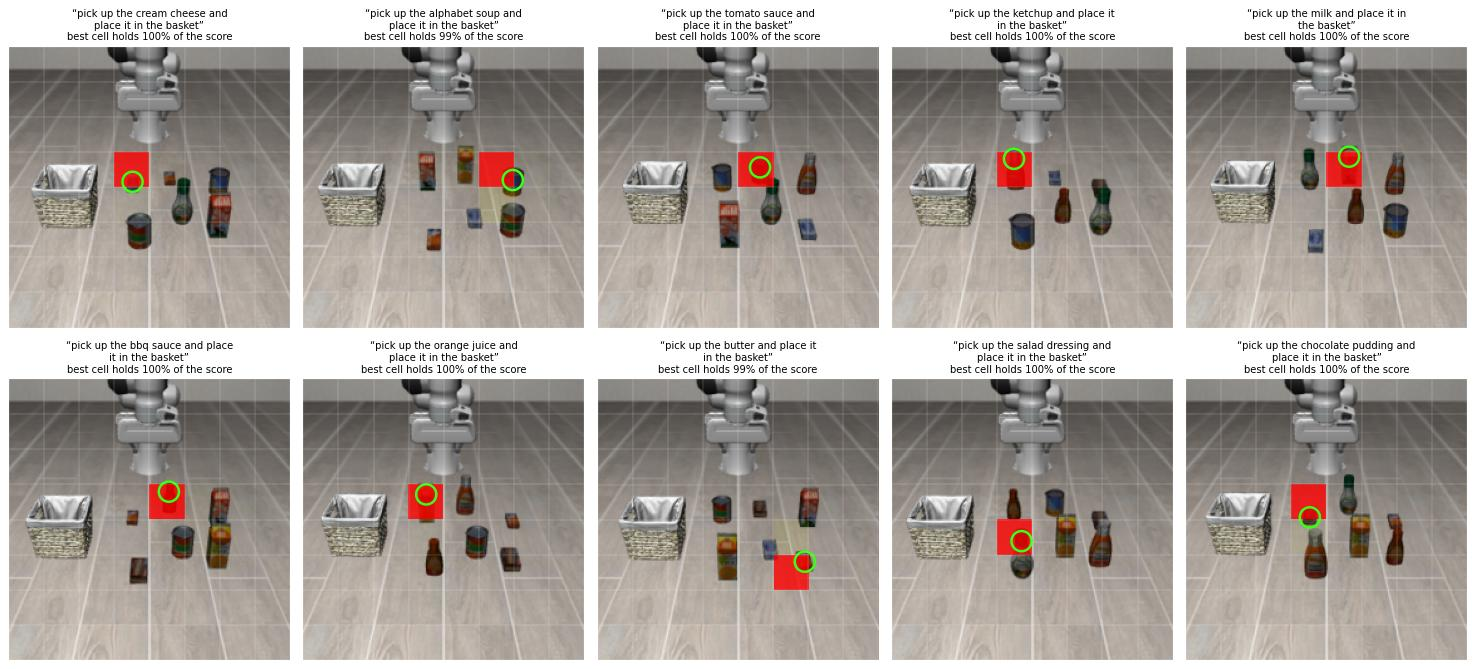

In [5]:
for label, suite in L.SUITES.items():
    print("map over image cells ·", label)
    P.map_figure(found[GRID], camera, P.items_of(found[GRID], f"pro {suite}", every=2))
    plt.show()

## 4 · Closed loop on LIBERO-PRO
**This step:** the plan is predicted from the images at run time and given to the action head; nothing comes from the simulator. Every task of the Object suite from 20 start states under each perturbation.

**Status:** real rollouts. The action head is the same in every column with a plan. "At every query" asks the predictor for a new plan every 8 steps. "Kept" predicts a plan once, keeps its contact in world coordinates until the gripper has carried out the event (it closed, or opened), and only then asks again. The last column is given the ORACLE plan.

In [6]:
PRO = ROOT / "runs" / "libero_pro"
RELEASED, ORACLE = "released policy, no plan", "ORACLE plan"
CANDIDATES = {RELEASED: "released",
              f"{REGRESS}, at every query": "predicted_p1", f"{REGRESS}, kept": "predicted_p1_hold",
              f"{GRID}, at every query": "predicted_g1", f"{GRID}, kept": "predicted_g1_hold",
              ORACLE: "oracle_plan_s2"}
FOLDERS = {name: PRO / folder for name, folder in CANDIDATES.items()
           if all(len(list((PRO / folder / suite).glob("task*_ep*.npz"))) >= 200 for suite in L.SUITES.values())}
runs = {name: {suite: L.load_suite(folder, suite) for suite in L.SUITES.values()} for name, folder in FOLDERS.items()}
display(L.score_table(runs).T)

,position: the target swaps places with another object,task: the instruction and the goal name another object
"released policy, no plan",0 / 200 = 0.00,20 / 200 = 0.10
"regressed contact, at every query",0 / 200 = 0.00,19 / 200 = 0.10
"map over image cells, at every query",72 / 200 = 0.36,90 / 200 = 0.45
"map over image cells, kept",102 / 200 = 0.51,113 / 200 = 0.56
ORACLE plan,164 / 200 = 0.82,136 / 200 = 0.68


**For comparison, what other papers report on LIBERO-PRO** (position and task perturbation; the Object suite is the second number of each cell). Quoted, not re-run; they use 50 trials per task and their baselines disagree with each other, so the comparison is loose.

In [7]:
display(L.published_table())

,what it is,position (Spatial / Object / Goal / LIBERO-10),task (Spatial / Object / Goal / LIBERO-10)
"π0.5, as reported in the GAM paper",official checkpoint,0.20 / 0.17 / 0.38 / 0.08,0.01 / 0.01 / 0.00 / 0.01
"π0.5, as reported in the CounterAlign paper",trained on LIBERO,0.53 / 0.19 / 0.29 / 0.06,0.55 / 0.10 / 0.17 / 0.17
GAM (arXiv 2609.23863),"not a VLA; 3D detector, simulator depth",0.60 / 0.47 / 0.19 / 0.05,0.88 / 0.50 / 0.16 / 0.08
CounterAlign (arXiv 2608.21740),π0.5 + offline RL,0.60 / 0.51 / 0.41 / 0.11,0.63 / 0.26 / 0.46 / 0.29
π0.5 + Affordance Field Intervention (arXiv 2512.07472),test-time depth and GPT-4o,0.76 / 0.73 / – / –,– / – / – / –


## 5 · Where the plans pointed during the rollouts
**This step:** every logged plan is turned back into the contact it pointed at and compared with the oracle grasp point of the object asked for, at every query before anything is held. First the plan of the first query of each rollout, then the error along the approach, then per task.

**Status:** real plans; the grasp points they are compared with are ORACLE. A grasp plan "points at" the object whose grasp point is nearest to it, if that is within 10 cm. In the figure, query n only counts the rollouts that had held nothing by then, so its later points rest on fewer and slower rollouts.

In [8]:
PREDICTED = [name for name in FOLDERS if name not in (RELEASED,)]
audits = {name: {suite: [P.grasp_plans(log, offsets) for log in runs[name][suite]] for suite in L.SUITES.values()}
          for name in PREDICTED}
for label, suite in L.SUITES.items():
    print(label)
    display(P.pointing_table({name: run[suite] for name, run in audits.items()}).T)

position: the target swaps places with another object


,"regressed contact, at every query","map over image cells, at every query","map over image cells, kept",ORACLE plan
rollouts,200,200,200,200
first plan is a grasp plan,200 / 200,200 / 200,200 / 200,200 / 200
first plan points at the named object,0 / 200,184 / 200,184 / 200,200 / 200
first plan points at another object,154 / 200,9 / 200,9 / 200,0 / 200
first plan: median error (cm),23.0,1.9,1.9,0.0
first plan within 2 cm,0 / 200,105 / 200,105 / 200,200 / 200
solved,0 / 200,72 / 200,102 / 200,164 / 200
solved when the first plan pointed at the named object,–,72 / 184,101 / 184,164 / 200
solved when it did not,0 / 200,0 / 16,1 / 16,–


task: the instruction and the goal name another object


,"regressed contact, at every query","map over image cells, at every query","map over image cells, kept",ORACLE plan
rollouts,200,200,200,200
first plan is a grasp plan,200 / 200,200 / 200,200 / 200,200 / 200
first plan points at the named object,141 / 200,200 / 200,200 / 200,200 / 200
first plan points at another object,45 / 200,0 / 200,0 / 200,0 / 200
first plan: median error (cm),3.2,1.3,1.3,0.0
first plan within 2 cm,78 / 200,173 / 200,173 / 200,200 / 200
solved,19 / 200,90 / 200,113 / 200,136 / 200
solved when the first plan pointed at the named object,18 / 141,90 / 200,113 / 200,136 / 200
solved when it did not,1 / 59,–,–,–


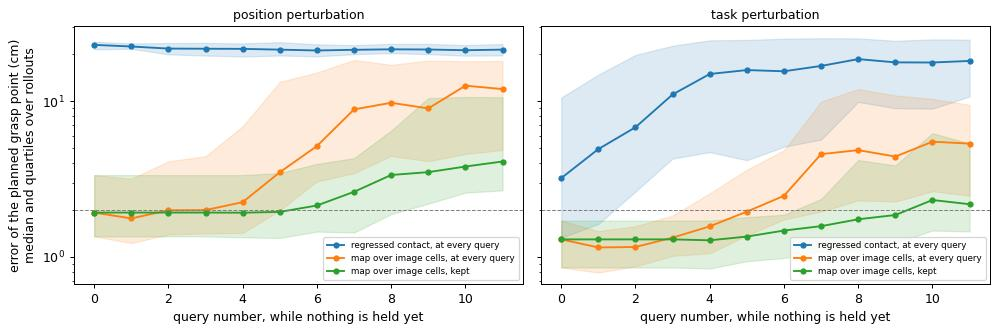

In [9]:
P.approach_figure({name: run for name, run in audits.items() if name != ORACLE})
plt.show()

In [10]:
for label, suite in L.SUITES.items():
    print(label)
    display(P.per_task_pointing({name: run[suite] for name, run in audits.items() if name != ORACLE}))

position: the target swaps places with another object


,asked for,"regressed contact, at every query","map over image cells, at every query","map over image cells, kept"
task,,,,
0,alphabet soup,plan right 0 · solved 0 / 20,plan right 20 · solved 11 / 20,plan right 20 · solved 17 / 20
1,cream cheese,plan right 0 · solved 0 / 20,plan right 20 · solved 11 / 20,plan right 20 · solved 15 / 20
2,salad dressing,plan right 0 · solved 0 / 20,plan right 20 · solved 2 / 20,plan right 20 · solved 3 / 20
3,bbq sauce,plan right 0 · solved 0 / 20,plan right 16 · solved 8 / 20,plan right 16 · solved 13 / 20
4,ketchup,plan right 0 · solved 0 / 20,plan right 20 · solved 0 / 20,plan right 20 · solved 1 / 20
5,tomato sauce,plan right 0 · solved 0 / 20,plan right 20 · solved 19 / 20,plan right 20 · solved 11 / 20
6,butter,plan right 0 · solved 0 / 20,plan right 14 · solved 0 / 20,plan right 14 · solved 12 / 20
7,milk,plan right 0 · solved 0 / 20,plan right 14 · solved 5 / 20,plan right 14 · solved 11 / 20
8,chocolate pudding,plan right 0 · solved 0 / 20,plan right 20 · solved 16 / 20,plan right 20 · solved 19 / 20


task: the instruction and the goal name another object


,asked for,"regressed contact, at every query","map over image cells, at every query","map over image cells, kept"
task,,,,
0,cream cheese,plan right 15 · solved 0 / 20,plan right 20 · solved 18 / 20,plan right 20 · solved 20 / 20
1,alphabet soup,plan right 20 · solved 18 / 20,plan right 20 · solved 20 / 20,plan right 20 · solved 20 / 20
2,tomato sauce,plan right 0 · solved 0 / 20,plan right 20 · solved 14 / 20,plan right 20 · solved 15 / 20
3,ketchup,plan right 20 · solved 0 / 20,plan right 20 · solved 1 / 20,plan right 20 · solved 3 / 20
4,milk,plan right 7 · solved 1 / 20,plan right 20 · solved 1 / 20,plan right 20 · solved 0 / 20
5,bbq sauce,plan right 19 · solved 0 / 20,plan right 20 · solved 3 / 20,plan right 20 · solved 0 / 20
6,orange juice,plan right 20 · solved 0 / 20,plan right 20 · solved 1 / 20,plan right 20 · solved 0 / 20
7,butter,plan right 0 · solved 0 / 20,plan right 20 · solved 20 / 20,plan right 20 · solved 20 / 20
8,salad dressing,plan right 20 · solved 0 / 20,plan right 20 · solved 2 / 20,plan right 20 · solved 18 / 20


## 6 · What happened to the object asked for
**This step:** the outcome of every rollout judged by what the gripper held: the named object was delivered (`success`), another object was grasped first (`wrong object`), nothing was held (`no grasp`), or the named object was held but did not end in the basket (`not delivered`). Then, for the policies with a plan, how far the rollouts got relative to the plan they were given.

**Status:** real. In the second table "the planned grasp point" is the one the policy was given, right or wrong: the row shows whether the action head went where the plan said.

In [11]:
for label, suite in L.SUITES.items():
    print(label)
    display(L.outcome_counts(runs, suite))
display(pd.DataFrame({f"{name}: {label.split(':')[0]}": L.stage_counts(folder, suite)
                      for name, folder in FOLDERS.items() if name != RELEASED for label, suite in L.SUITES.items()}))

position: the target swaps places with another object


,wrong object,no grasp,rollouts,success,not delivered
"released policy, no plan",195,5,200,0,0
"regressed contact, at every query",97,103,200,0,0
"map over image cells, at every query",7,85,200,72,36
"map over image cells, kept",4,51,200,102,43
ORACLE plan,0,17,200,164,19


task: the instruction and the goal name another object


,wrong object,success,no grasp,rollouts,not delivered
"released policy, no plan",175,20,5,200,0
"regressed contact, at every query",27,19,147,200,7
"map over image cells, at every query",6,89,81,200,24
"map over image cells, kept",12,113,41,200,34
ORACLE plan,0,136,28,200,36


,"regressed contact, at every query: position","regressed contact, at every query: task","map over image cells, at every query: position","map over image cells, at every query: task","map over image cells, kept: position","map over image cells, kept: task",ORACLE plan: position,ORACLE plan: task
rollouts,200,200,200,200,200,200,200,200
gripper came within 2 cm of the planned grasp point,102,140,122,124,160,158,193,187
object knocked over before it was held,2,50,57,54,21,30,33,52
object held,0,26,108,113,145,147,183,172
object in the basket at the end,0,19,72,90,102,113,164,136
"held, then let go outside the basket",0,6,22,18,36,32,16,22
"held, still in the gripper at the end",0,1,14,6,7,2,3,14


In [12]:
TASK = 2   # the salad dressing task in both suites
SHOWN = [name for name in FOLDERS if name not in (RELEASED, ORACLE)][-2:]
clips = {f"{name} - {label.split(':')[0]}": load_rollout_log(FOLDERS[name] / suite / f"task{TASK}_ep0.npz")
         for label, suite in L.SUITES.items() for name in SHOWN}
CLIP = ROOT / "report" / "media" / "plan_predictor_closed_loop.mp4"   # tracked in git
H.render_rollout_grid(list(clips.values()), list(clips), CLIP)
Video(str(CLIP), embed=True, width=1100)

## 7 · A second action head: moved plans that come down from above, and moved releases
**Why:** with a right plan, most remaining failures of the action head are tall objects knocked over before they are held, and objects let go outside the basket (section 6, last column; the notebook of 12 Nov). The action labels for a moved plan are the demonstrated path moved to the new contact. With the rule used so far the shift is blended in until the last 8 cm, and with less than 8 cm left it is put into the next step while the descent goes on. So the labels ask the gripper to come down while it is still to the side. Moved plans also only covered the way to the grasp, not the carry to the basket.

**This step:** two changes to the labels, and an action head trained with both (`s8_align_release`), on the same six tasks and for the same 2400 steps as the head of 11 Nov:
- **Align first:** a shift that does not fit into the path before the last 18 cm is made first, in a straight line, and the demonstrated approach follows, moved (`affordance3d/counterfactual.py`, `--align-first --rigid-tail 0.18`).
- **Moved releases:** frames in which the object is carried are also paired with a release point moved within the same 18 cm disc (`--counterfactual shift+other+release`).
- In the same commit a label error was fixed: when a moved path needs more steps than the demonstration had left, those steps used to get the demonstration's commands from after its grasp (lifting) added to them. The heads of 11 Nov had that error; a head with the fix alone is still training (`s2b_actions`).

**Status:** the figure and the first table are real demonstrations and real rollouts; the moved paths are what the labels ask for. The rollouts of section 7 are real; their plans are ORACLE unless a column says "map over image cells".

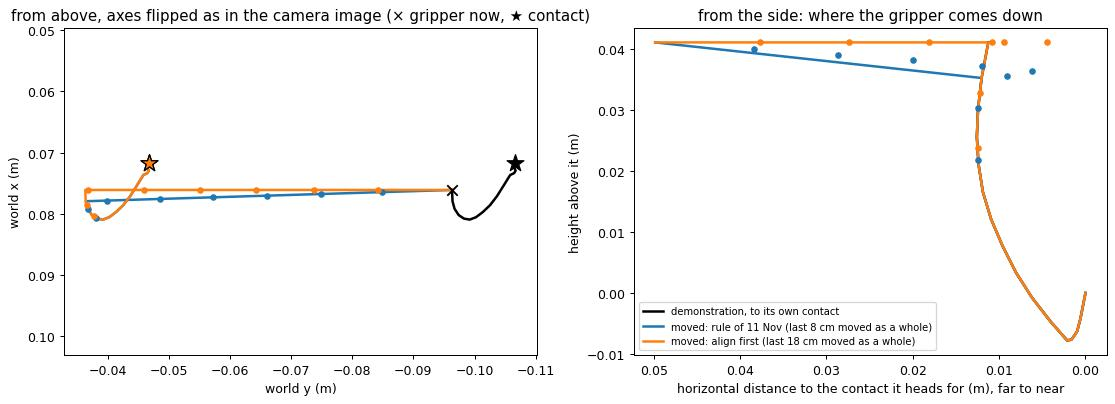

In [13]:
from affordance3d.counterfactual import Retarget
from affordance3d.plan_dataset import load_tracks

tracks = load_tracks(ROOT / "runs" / "plan_following" / "dataset" / "tracks.npz")
track = next((t for t in tracks if t.target == "salad_dressing_1"), None)
assert track is not None, "no salad dressing demonstration in the dataset"
grasp = track.labels[0].event.step
path = track.ee_pos[grasp - 16:grasp + 1]   # 16 steps before the grasp
RULES = {"rule of 11 Nov (last 8 cm moved as a whole)": Retarget(),
         "align first (last 18 cm moved as a whole)": Retarget(rigid_tail=0.18, align_first=True)}
SHIFT = np.array([0.0, 0.06, 0.0])   # the contact moved 6 cm sideways, 16 steps before the grasp
P.retarget_figure(path, path[-1] + SHIFT, RULES)
plt.show()

**How high the gripper is as it closes in on a tall object.** For every rollout and every demonstration whose named object is tall (bbq sauce, ketchup, milk, orange juice, salad dressing): the height above the grasp point, where the object is at that step, when the gripper first comes within 12, 9, 6, 4 and 2 cm of it horizontally, before it first touches the object. Median in cm over the rollouts that came that close; "came within 2 cm" counts them for the last column.

In [14]:
TALL_WORDS = [name[:-2] for name in P.TALL_OBJECTS]
DEMOS = ROOT / "runs" / "plan_following" / "demos"
demos = [load_rollout_log(path, images=False) for path in sorted(DEMOS.glob("*_demo*.npz"))
         if any(path.name.startswith(f"pick_up_the_{word}_and_") for word in TALL_WORDS)]
HEADS = {"head of 11 Nov + ORACLE plan": PRO / "oracle_plan_s2",
         "head of 13 Nov + ORACLE plan": PRO / "oracle_plan_s8"}
complete = lambda folder: all(len(list((folder / suite).glob("task*_ep*.npz"))) >= 200  # noqa: E731
                              for suite in L.SUITES.values())
print("not complete, left out:", [name for name, folder in HEADS.items() if not complete(folder)])
HEADS = {name: folder for name, folder in HEADS.items() if complete(folder)}
tall = {"demonstrations": demos}
for name, folder in HEADS.items():
    for label, suite in L.SUITES.items():
        logs = L.load_suite(folder, suite)
        tall[f"{name}, {label.split(':')[0]}"] = [log for log in logs if log.target in P.TALL_OBJECTS]
display(P.approach_height_table(tall, offsets))

not complete, left out: []


,rollouts,came within 2 cm,within 12 cm,within 9 cm,within 6 cm,within 4 cm,within 2 cm
demonstrations,250,229,14.9,14.7,14.3,13.5,11.8
"head of 11 Nov + ORACLE plan, position",100,59,14.8,14.3,13.0,4.7,3.0
"head of 11 Nov + ORACLE plan, task",100,34,16.2,14.6,14.6,1.5,2.2
"head of 13 Nov + ORACLE plan, position",100,100,15.5,15.4,15.1,14.6,12.2
"head of 13 Nov + ORACLE plan, task",100,87,16.2,15.7,15.1,14.7,13.0


**On the six training tasks** (the experiment of 11 Nov: the same 5 standard starts, the target moved 4–16 cm from 6 starts, another object named from 6 starts; ORACLE plan). One row per head; a success is the named object grasped first and left in the basket.

In [15]:
from report import plan_following_helpers as F

SIX = ROOT / "runs" / "plan_following"
SIX_HEADS = {"11 Nov: moved grasps": "s2_actions", "moved grasps, label fix": "s2b_actions",
             "moved grasps and releases (labels before the fix)": "s6_release",
             "align first, label fix": "s7_align", "13 Nov: align first + moved releases, label fix": "s8_align_release"}
def rollout_folders(run):
    return tuple(folder for folder in (SIX / run / "rollouts_oracle", SIX / run / "rollouts_oracle_more")
                 if folder.is_dir())


print("not run yet, left out:", [name for name, run in SIX_HEADS.items() if not rollout_folders(run)])
SIX_HEADS = {name: run for name, run in SIX_HEADS.items() if rollout_folders(run)}
six = {name: F.merge_runs(*[F.load_run(folder) for folder in rollout_folders(run)]) for name, run in SIX_HEADS.items()}
display(F.success_table(six))
for set_name in F.PERTURBED_SETS:
    print(set_name)
    display(F.stage_table({name: rollout_folders(run) for name, run in SIX_HEADS.items()}, set_name))

not run yet, left out: ['moved grasps, label fix']


,11 Nov: moved grasps,moved grasps and releases (labels before the fix),"align first, label fix","13 Nov: align first + moved releases, label fix"
standard,5 / 5,5 / 5,5 / 5,5 / 5
target moved 4–16 cm,15 / 18,16 / 18,15 / 18,13 / 18
another object named,20 / 30,24 / 30,19 / 30,22 / 30


target moved 4–16 cm


,rollouts,gripper came within 2 cm of the planned grasp point,object knocked over before it was held,object held,object delivered,"held, then let go outside the basket","held, still in the gripper at the end"
11 Nov: moved grasps,18,18,0,18,15,3,0
moved grasps and releases (labels before the fix),18,18,1,17,16,1,0
"align first, label fix",18,18,1,18,15,3,0
"13 Nov: align first + moved releases, label fix",18,18,0,15,13,1,1


another object named


,rollouts,gripper came within 2 cm of the planned grasp point,object knocked over before it was held,object held,object delivered,"held, then let go outside the basket","held, still in the gripper at the end"
11 Nov: moved grasps,30,27,0,26,20,4,2
moved grasps and releases (labels before the fix),30,28,0,27,24,1,2
"align first, label fix",30,25,0,27,19,4,4
"13 Nov: align first + moved releases, label fix",30,26,0,26,22,3,1


**On LIBERO-PRO Object** (10 tasks × 20 starts per perturbation): the head of 13 Nov with the ORACLE plan and with the plans of the map head, kept per phase, next to the head of 11 Nov.

In [16]:
SECOND = {"head of 11 Nov + map, kept": "predicted_g1_hold", "head of 13 Nov + map, kept": "predicted_g1_hold_s8",
          "head of 11 Nov + ORACLE plan": "oracle_plan_s2", "head of 13 Nov + ORACLE plan": "oracle_plan_s8",
          "11 Nov, moved releases + ORACLE plan": "oracle_plan_s6"}
print("not complete, left out:", [name for name, run in SECOND.items() if not complete(PRO / run)])
SECOND = {name: PRO / run for name, run in SECOND.items() if complete(PRO / run)}
second = {name: {suite: L.load_suite(folder, suite) for suite in L.SUITES.values()} for name, folder in SECOND.items()}
display(L.score_table(second).T)
for label, suite in L.SUITES.items():
    print(label)
    display(L.outcome_counts(second, suite))
display(pd.DataFrame({f"{name}: {label.split(':')[0]}": L.stage_counts(folder, suite)
                      for name, folder in SECOND.items() for label, suite in L.SUITES.items()}))

not complete, left out: []


,position: the target swaps places with another object,task: the instruction and the goal name another object
"head of 11 Nov + map, kept",102 / 200 = 0.51,113 / 200 = 0.56
"head of 13 Nov + map, kept",113 / 200 = 0.56,130 / 200 = 0.65
head of 11 Nov + ORACLE plan,164 / 200 = 0.82,136 / 200 = 0.68
head of 13 Nov + ORACLE plan,175 / 200 = 0.88,141 / 200 = 0.70
"11 Nov, moved releases + ORACLE plan",154 / 200 = 0.77,142 / 200 = 0.71


position: the target swaps places with another object


,success,no grasp,not delivered,wrong object,rollouts
"head of 11 Nov + map, kept",102,51,43,4,200
"head of 13 Nov + map, kept",112,51,33,4,200
head of 11 Nov + ORACLE plan,164,17,19,0,200
head of 13 Nov + ORACLE plan,175,4,21,0,200
"11 Nov, moved releases + ORACLE plan",154,27,19,0,200


task: the instruction and the goal name another object


,success,no grasp,not delivered,wrong object,rollouts
"head of 11 Nov + map, kept",113,41,34,12,200
"head of 13 Nov + map, kept",130,31,35,4,200
head of 11 Nov + ORACLE plan,136,28,36,0,200
head of 13 Nov + ORACLE plan,141,34,25,0,200
"11 Nov, moved releases + ORACLE plan",142,29,29,0,200


,"head of 11 Nov + map, kept: position","head of 11 Nov + map, kept: task","head of 13 Nov + map, kept: position","head of 13 Nov + map, kept: task",head of 11 Nov + ORACLE plan: position,head of 11 Nov + ORACLE plan: task,head of 13 Nov + ORACLE plan: position,head of 13 Nov + ORACLE plan: task,"11 Nov, moved releases + ORACLE plan: position","11 Nov, moved releases + ORACLE plan: task"
rollouts,200,200,200,200,200,200,200,200,200,200
gripper came within 2 cm of the planned grasp point,160,158,179,185,193,187,199,197,196,178
object knocked over before it was held,21,30,14,10,33,52,8,19,42,49
object held,145,147,145,165,183,172,196,166,173,171
object in the basket at the end,102,113,113,130,164,136,175,141,154,142
"held, then let go outside the basket",36,32,17,11,16,22,10,12,18,21
"held, still in the gripper at the end",7,2,16,24,3,14,11,13,1,8


## What to take from this

**What this run shows**
- **A plan read from a map over image cells survives the perturbations; a regressed contact does not.** On the first frames of the position perturbation the regressed contact points at another object in 20 of 20 frames (median error 22.9 cm), the map head in 2 of 20 (1.9 cm). In the closed loop, the first plan points at the named object in 184 of 200 rollouts with the map head and in 0 of 200 with the regressed contact; under the task perturbation in 200 and 141 of 200.
- **With predicted plans the action head now solves perturbed tasks without any oracle plan.** With the regressed contact it does no better than the released policy (0 and 19 of 200, against 0 and 20). With the map head it solves 72 and 90 of 200 when a plan is predicted at every query, and 102 and 113 of 200 when each plan is kept until the gripper has closed or opened.
- **Keeping the plan helps because the predictor only saw demonstration frames.** Once the arm follows a moved plan, its camera images are ones no demonstration contains, and the error of a plan predicted from them grows along the approach (section 5, figure). The contact of a grasp does not move before the grasp, so a plan predicted at the start stays valid.
- **The remaining gap to the oracle plan is mostly in tall objects.** With kept plans, the first plan points at the named object in all 20 rollouts of the ketchup, orange juice and salad dressing tasks under the position perturbation, yet only 1, 0 and 3 of 20 are solved. Under the task perturbation the ketchup, milk, bbq sauce and orange juice tasks have 3, 0, 0 and 0 of 20. A tall object tolerates less error at the grasp point than a can or a box.
- **The labels of moved plans made the gripper come down beside tall objects; the align-first rule fixes that.** When the gripper is 4 cm away horizontally from a tall object's grasp point, the demonstrations are 13.5 cm above it, the head of 11 Nov 4.7 cm (position) and 1.5 cm (task), and the head of 13 Nov 14.6 and 14.7 cm. Before touching the object, the head of 11 Nov got within 2 cm of the grasp point in only 59 and 34 of 100 such rollouts, the head of 13 Nov in 100 and 87. With the oracle plan, tall objects are knocked over before they are held in 8 instead of 33 rollouts (position) and 19 instead of 52 (task).
- **The head of 13 Nov raises every column.** With the oracle plan it solves 175 and 141 of 200 (11 Nov: 164 and 136); with kept plans of the map head 113 and 130 of 200 (102 and 113). The latter is the first number of this project that rests on no oracle plan: 0.56 and 0.65. On this suite the papers report 0.47 (GAM), 0.51 (CounterAlign) and 0.73 (π0.5 with a test-time affordance field, which uses depth and GPT-4o) under the position perturbation, and 0.50 and 0.26 under the task perturbation. So it lies above two of the three, under a looser protocol (see below).

**What it does not show**
- **Which change gives the gain of the head of 13 Nov.** It differs from the head of 11 Nov in three ways: the align-first rule, moved releases, and the label fix. Moved releases alone, with the labels before the fix, did not clearly help: 154 and 142 of 200 against 164 and 136, and as many objects let go outside the basket. The controls for the align-first rule (`s7_align`) and the label fix (`s2b_actions`) are still running.
- **On the six training tasks the heads cannot be told apart** (13–16 of 18, 19–24 of 30): that set is too small to rank them.
- **That the gains of the head of 13 Nov are more than noise.** With 200 rollouts per column, the standard error of the difference between two columns is about 7 to 10 rollouts; the gains (5 to 17 rollouts) are within two of them, from one run with one seed. The drop in knocked-over objects (33 to 8, 52 to 19: about four standard errors) and the difference between the two plan heads (0 against 184 right first plans) are not.
- **A comparison under the papers' protocol.** Here: 20 starts per task instead of 50, one suite of four, one seed. The map head turns a pixel and a depth into a 3D point with the simulator's camera calibration; nothing else comes from the simulator at run time. The action heads saw six of the ten tasks, the plan heads the demonstrations of all ten. Which instruction the papers fed under the task perturbation is not known.

**Next**
1. Finish the attribution: the align-first head and the label-fix head on LIBERO-PRO with the oracle plan (running).
2. Train the plan predictor also on frames of closed-loop rollouts, so that a plan predicted at every query is as good as a kept one.
3. Tall objects: the error of the predicted grasp point on them, and whether a finer map (more cells, or the wrist camera) closes the gap.
4. A ten-task action head with the new labels; then the other three suites, and the papers' protocol (50 starts, three seeds).